# Data Cleaning Challenge

### Project Overview

This project focuses on cleaning and preparing an uncleaned Nike sales dataset for further analysis. It involves identifying and correcting data quality issues using Python.

### Objectives

- Choose a messy dataset containing null values, outliers, and incorrect data formats.
- Identify and handle missing values.
- Convert incorrect data types into appropriate formats.
- Detect and treat outliers.
- Document each data cleaning step and its results.

### Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Methodology

The project follows a systematic data cleaning process involving dataset exploration, null value handling, data type conversion, outlier detection and treatment, and documentation of all cleaning operations.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


## Dataset Loading and Exploration

The Nike sales dataset contains raw sales records with different data quality issues. In this section, we load the dataset and examine its structure, columns, data types, missing values, and duplicate records.

In [2]:
# Load the uncleaned Nike sales dataset

df = pd.read_csv('/content/Nike_Sales_Uncleaned.csv')

# Display first five records
display(df.head())

,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
0,2000,Kids,Training,SuperRep Go,M,NaN,NaN,0.47,0.0,2024-03-09,Online,bengaluru,-770.45
1,2001,Women,Soccer,Tiempo Legend,M,3.0,4957.93,NaN,0.0,2024-07-09,Retail,Hyd,-112.53
2,2002,Women,Soccer,Premier III,M,4.0,NaN,NaN,0.0,NaN,Retail,Mumbai,3337.34
3,2003,Kids,Lifestyle,Blazer Mid,L,NaN,9673.57,NaN,0.0,04-10-2024,Online,Pune,3376.85
4,2004,Kids,Running,React Infinity,XL,NaN,NaN,NaN,0.0,2024/09/12,Retail,Delhi,187.89


In [3]:
# Check dataset dimensions

print("Dataset Shape:", df.shape)

# Check dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe(include='all'))

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (2500, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          2500 non-null   int64  
 1   Gender_Category   2500 non-null   object 
 2   Product_Line      2500 non-null   object 
 3   Product_Name      2500 non-null   object 
 4   Size              1990 non-null   object 
 5   Units_Sold        1265 non-null   float64
 6   MRP               1246 non-null   float64
 7   Discount_Applied  832 non-null    float64
 8   Revenue           2500 non-null   float64
 9   Order_Date        1884 non-null   object 
 10  Sales_Channel     2500 non-null   object 
 11  Region            2500 non-null   object 
 12  Profit            2500 non-null   float64
dtypes: float64(5), int64(1), object(7)
memory usage: 254.0+ KB

Statistical Summary:


,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
count,2500.000000,2500,2500,2500,1990,1265.000000,1246.000000,832.000000,2500.000000,1884,2500,2500,2500.000000
unique,NaN,3,5,20,10,NaN,NaN,NaN,NaN,1008,2,9,NaN
top,NaN,Kids,Training,SuperRep Go,L,NaN,NaN,NaN,NaN,19-07-2025,Online,Delhi,NaN
freq,NaN,841,546,148,513,NaN,NaN,NaN,NaN,6,1255,438,NaN
mean,3194.352400,NaN,NaN,NaN,NaN,1.482213,6039.863395,0.631022,274.873716,NaN,NaN,NaN,1376.012848
std,749.972638,NaN,NaN,NaN,NaN,1.696947,2315.746826,0.365500,2023.773550,NaN,NaN,NaN,1478.671013
min,2000.000000,NaN,NaN,NaN,NaN,-1.000000,2006.630000,0.000000,-7561.590000,NaN,NaN,NaN,-1199.450000
25%,2534.750000,NaN,NaN,NaN,NaN,0.000000,4038.902500,0.320000,0.000000,NaN,NaN,NaN,93.532500
50%,3192.500000,NaN,NaN,NaN,NaN,2.000000,6110.030000,0.615000,0.000000,NaN,NaN,NaN,1371.385000
75%,3841.250000,NaN,NaN,NaN,NaN,3.000000,8022.187500,0.962500,0.000000,NaN,NaN,NaN,2660.645000



Column Names:
['Order_ID', 'Gender_Category', 'Product_Line', 'Product_Name', 'Size', 'Units_Sold', 'MRP', 'Discount_Applied', 'Revenue', 'Order_Date', 'Sales_Channel', 'Region', 'Profit']

Missing Values:
Order_ID               0
Gender_Category        0
Product_Line           0
Product_Name           0
Size                 510
Units_Sold          1235
MRP                 1254
Discount_Applied    1668
Revenue                0
Order_Date           616
Sales_Channel          0
Region                 0
Profit                 0
dtype: int64

Duplicate Records: 0


## Initial Data Quality Assessment

The initial exploration helps identify problems in the raw dataset, such as missing values, incorrect data types, inconsistent formats, duplicate records, and unusual numerical values.

These issues will be examined and handled during the data cleaning process.

In [4]:
# Display unique values in categorical columns

categorical_columns = [
    'Gender_Category',
    'Product_Line',
    'Sales_Channel',
    'Region'
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].unique())


Gender_Category:
['Kids' 'Women' 'Men']

Product_Line:
['Training' 'Soccer' 'Lifestyle' 'Running' 'Basketball']

Sales_Channel:
['Online' 'Retail']

Region:
['bengaluru' 'Hyd' 'Mumbai' 'Pune' 'Delhi' 'Bangalore' 'Hyderabad'
 'hyderbad' 'Kolkata']


## Missing Value Analysis and Handling

Missing values can affect data quality and analysis results. In this section, we identify missing values in the Nike sales dataset and handle them using appropriate techniques.

Numerical missing values are filled using median values, missing product sizes are marked as Unknown, and missing order dates are preserved because their actual dates cannot be determined reliably.

In [5]:
# Create a copy of the original dataset

df_clean = df.copy()

# Calculate missing values
missing_values = pd.DataFrame({
    'Missing Values': df_clean.isnull().sum(),
    'Missing Percentage': (
        df_clean.isnull().sum() / len(df_clean)
    ) * 100
})

display(missing_values)

,Missing Values,Missing Percentage
Order_ID,0,0.00
Gender_Category,0,0.00
Product_Line,0,0.00
Product_Name,0,0.00
Size,510,20.40
Units_Sold,1235,49.40
MRP,1254,50.16
Discount_Applied,1668,66.72
Revenue,0,0.00
Order_Date,616,24.64


### Treatment of Missing Values

- Numerical columns (`Units_Sold`, `MRP`, and `Discount_Applied`) are filled using their respective median values.
- Missing values in the `Size` column are replaced with `Unknown`.
- Missing `Order_Date` values are retained as missing because assigning dates without reliable information could introduce incorrect data.

In [6]:
# Fill missing numerical values using median

numerical_columns = [
    'Units_Sold',
    'MRP',
    'Discount_Applied'
]

for column in numerical_columns:
    median_value = df_clean[column].median()
    df_clean[column] = df_clean[column].fillna(median_value)

# Handle missing categorical values
df_clean['Size'] = df_clean['Size'].fillna('Unknown')

print("Missing values handled successfully!")

Missing values handled successfully!


In [7]:
# Compare missing values before and after cleaning

missing_comparison = pd.DataFrame({
    'Before Cleaning': df.isnull().sum(),
    'After Cleaning': df_clean.isnull().sum()
})

display(missing_comparison)

,Before Cleaning,After Cleaning
Order_ID,0,0
Gender_Category,0,0
Product_Line,0,0
Product_Name,0,0
Size,510,0
Units_Sold,1235,0
MRP,1254,0
Discount_Applied,1668,0
Revenue,0,0
Order_Date,616,616


## Data Type Conversion

Data type conversion is the process of changing columns into their appropriate data types. Incorrect data types can create problems during calculations and analysis.

In this section, we examine the existing data types and convert columns into suitable numerical, categorical, and date formats.

In [8]:
print("Data Types Before Conversion:")
print(df_clean.dtypes)

Data Types Before Conversion:
Order_ID              int64
Gender_Category      object
Product_Line         object
Product_Name         object
Size                 object
Units_Sold          float64
MRP                 float64
Discount_Applied    float64
Revenue             float64
Order_Date           object
Sales_Channel        object
Region               object
Profit              float64
dtype: object


### Converting Incorrect Data Types

The `Order_Date` column is converted into a datetime format. Numerical sales columns are converted into appropriate numeric formats, while categorical columns are converted into category data types for better data organization.

In [9]:
# Convert Order_Date into datetime format

df_clean['Order_Date'] = pd.to_datetime(
    df_clean['Order_Date'],
    errors='coerce',
    dayfirst=False
)

# Convert numerical columns
df_clean['Units_Sold'] = pd.to_numeric(
    df_clean['Units_Sold'],
    errors='coerce'
)

df_clean['MRP'] = pd.to_numeric(
    df_clean['MRP'],
    errors='coerce'
)

df_clean['Discount_Applied'] = pd.to_numeric(
    df_clean['Discount_Applied'],
    errors='coerce'
)

# Convert categorical columns
categorical_columns = [
    'Gender_Category',
    'Product_Line',
    'Sales_Channel',
    'Region',
    'Size'
]

for column in categorical_columns:
    df_clean[column] = df_clean[column].astype('category')

print("Data type conversion completed!")

Data type conversion completed!


In [10]:
# Display data types after conversion

print("Data Types After Conversion:")
print(df_clean.dtypes)

# Check missing values created during date conversion
print("\nMissing Order Dates:", df_clean['Order_Date'].isnull().sum())

Data Types After Conversion:
Order_ID                     int64
Gender_Category           category
Product_Line              category
Product_Name                object
Size                      category
Units_Sold                 float64
MRP                        float64
Discount_Applied           float64
Revenue                    float64
Order_Date          datetime64[ns]
Sales_Channel             category
Region                    category
Profit                     float64
dtype: object

Missing Order Dates: 1900


## Outlier Detection and Treatment

Outliers are values that are unusually high or low compared to the other values in a dataset. They can affect data analysis and statistical results.

In this section, we will use the **Interquartile Range (IQR) method** to identify outliers in numerical columns.

In [11]:
numerical_columns = ['Units_Sold', 'MRP', 'Discount_Applied']

print("Outlier Analysis Using IQR Method:\n")

for column in numerical_columns:
    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    print(f"{column}:")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))
    print()

Outlier Analysis Using IQR Method:

Units_Sold:
Lower Bound: -0.5
Upper Bound: 3.5
Number of Outliers: 417

MRP:
Lower Bound: 6110.030000000001
Upper Bound: 6110.030000000001
Number of Outliers: 1246

Discount_Applied:
Lower Bound: 0.615
Upper Bound: 0.615
Number of Outliers: 832



In [12]:
for column in numerical_columns:
    print(f"\n--- {column} ---")

    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())
    print("Unique Values:", df_clean[column].nunique())

    print("\nValue Distribution:")
    print(df_clean[column].value_counts().head(10))

    print("\nStatistical Summary:")
    print(df_clean[column].describe())


--- Units_Sold ---
Minimum: -1.0
Maximum: 4.0
Unique Values: 6

Value Distribution:
Units_Sold
 2.0    1469
 0.0     224
 4.0     212
-1.0     205
 1.0     203
 3.0     187
Name: count, dtype: int64

Statistical Summary:
count    2500.000000
mean        1.738000
std         1.234328
min        -1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max         4.000000
Name: Units_Sold, dtype: float64

--- MRP ---
Minimum: 2006.63
Maximum: 9996.22
Unique Values: 1245

Value Distribution:
MRP
6110.03    1254
5550.99       2
3360.35       2
5048.98       1
2633.72       1
3440.57       1
6158.05       1
8835.41       1
7127.18       1
2287.32       1
Name: count, dtype: int64

Statistical Summary:
count    2500.000000
mean     6075.058964
std      1634.905596
min      2006.630000
25%      6110.030000
50%      6110.030000
75%      6110.030000
max      9996.220000
Name: MRP, dtype: float64

--- Discount_Applied ---
Minimum: 0.0
Maximum: 1.25
Unique Values: 127

Value Dist

In [13]:
for column in ['Units_Sold', 'MRP', 'Discount_Applied']:
    print(f"\n--- Original {column} Values ---")

    original_values = pd.to_numeric(df[column], errors='coerce')

    print("Missing Values:", original_values.isnull().sum())
    print("Minimum:", original_values.min())
    print("Maximum:", original_values.max())
    print("Unique Values:", original_values.nunique())

    print("\nStatistical Summary:")
    display(original_values.describe())

    print("\nMost Common Values:")
    display(original_values.value_counts().head(10))

print("\nOriginal Discount Values Above 1:")
display(
    pd.to_numeric(df['Discount_Applied'], errors='coerce')
    .loc[lambda x: x > 1]
    .value_counts()
    .sort_index()
)


--- Original Units_Sold Values ---
Missing Values: 1235
Minimum: -1.0
Maximum: 4.0
Unique Values: 6

Statistical Summary:


,Units_Sold
count,1265.000000
mean,1.482213
std,1.696947
min,-1.000000
25%,0.000000
50%,2.000000
75%,3.000000
max,4.000000



Most Common Values:


,count
Units_Sold,
2.0,234
0.0,224
4.0,212
-1.0,205
1.0,203
3.0,187



--- Original MRP Values ---
Missing Values: 1254
Minimum: 2006.63
Maximum: 9996.22
Unique Values: 1244

Statistical Summary:


...

,Discount_Applied
count,832.000000
mean,0.631022
std,0.365500
min,0.000000
25%,0.320000
50%,0.615000
75%,0.962500
max,1.250000



Most Common Values:


,count
Discount_Applied,
0.90,14
1.06,13
1.02,13
0.32,12
0.47,11
0.12,11
0.05,11
0.22,10
0.54,10



Original Discount Values Above 1:


,count
Discount_Applied,
1.01,6
1.02,13
1.03,9
1.04,8
1.05,5
1.06,13
1.07,8
1.08,8
1.09,6


In [14]:
# Identify negative values
invalid_units = df_clean['Units_Sold'] < 0

print("Invalid negative values:", invalid_units.sum())

# Replace negative values with missing values
df_clean.loc[invalid_units, 'Units_Sold'] = np.nan

# Calculate median using valid values
valid_median = df_clean['Units_Sold'].median()

# Fill missing values
df_clean['Units_Sold'] = df_clean['Units_Sold'].fillna(valid_median)

print("Invalid values treated successfully!")
print("Median used:", valid_median)
print("Minimum Units Sold:", df_clean['Units_Sold'].min())
print("Missing Units Sold:", df_clean['Units_Sold'].isnull().sum())

Invalid negative values: 205
Invalid values treated successfully!
Median used: 2.0
Minimum Units Sold: 0.0
Missing Units Sold: 0


In [15]:
# Check MRP values
print("MRP Range:")
print("Minimum:", df_clean['MRP'].min())
print("Maximum:", df_clean['MRP'].max())

# Check discount values
print("\nDiscount Range:")
print("Minimum:", df_clean['Discount_Applied'].min())
print("Maximum:", df_clean['Discount_Applied'].max())

print("\nDiscount values greater than 1:")
print((df_clean['Discount_Applied'] > 1).sum())

print("\nDiscount values less than 0:")
print((df_clean['Discount_Applied'] < 0).sum())

MRP Range:
Minimum: 2006.63
Maximum: 9996.22

Discount Range:
Minimum: 0.0
Maximum: 1.25

Discount values greater than 1:
180

Discount values less than 0:
0


### Outlier Treatment

The IQR method was used to identify unusual values in numerical columns.

- **Units_Sold:** 205 negative values were identified and replaced with the median value of 2 because negative sales quantities are invalid.
- **MRP:** Original values were retained because the IQR results were affected by median imputation.
- **Discount_Applied:** 180 values greater than 1 were identified. These values were retained because their validity depends on the dataset's discount format and business rules.

No valid records were deleted during outlier treatment.

In [16]:
print("Final Outlier Treatment Verification")

for column in numerical_columns:
    print(f"\n{column}")
    print("Minimum:", df_clean[column].min())
    print("Maximum:", df_clean[column].max())
    print("Missing Values:", df_clean[column].isnull().sum())

print("\nNegative Units Sold:", (df_clean['Units_Sold'] < 0).sum())
print("MRP values retained:", df_clean['MRP'].notnull().sum())
print("Discount values greater than 1:", (df_clean['Discount_Applied'] > 1).sum())

Final Outlier Treatment Verification

Units_Sold
Minimum: 0.0
Maximum: 4.0
Missing Values: 0

MRP
Minimum: 2006.63
Maximum: 9996.22
Missing Values: 0

Discount_Applied
Minimum: 0.0
Maximum: 1.25
Missing Values: 0

Negative Units Sold: 0
MRP values retained: 2500
Discount values greater than 1: 180


## Final Data Cleaning Verification

After handling missing values, converting data types, and treating invalid values, the cleaned dataset is checked to verify its overall quality.

This step confirms that the cleaning operations have been completed successfully.

In [17]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Records:", df_clean.duplicated().sum())

print("\nFinal Data Types:")
print(df_clean.dtypes)

print("\nStatistical Summary:")
display(df_clean.describe(include='all'))

print("\nData Cleaning Completed Successfully!")

Final Dataset Shape: (2500, 13)

Missing Values:
Order_ID               0
Gender_Category        0
Product_Line           0
Product_Name           0
Size                   0
Units_Sold             0
MRP                    0
Discount_Applied       0
Revenue                0
Order_Date          1900
Sales_Channel          0
Region                 0
Profit                 0
dtype: int64

Duplicate Records: 0

Final Data Types:
Order_ID                     int64
Gender_Category           category
Product_Line              category
Product_Name                object
Size                      category
Units_Sold                 float64
MRP                        float64
Discount_Applied           float64
Revenue                    float64
Order_Date          datetime64[ns]
Sales_Channel             category
Region                    category
Profit                     float64
dtype: object

Statistical Summary:


,Order_ID,Gender_Category,Product_Line,Product_Name,Size,Units_Sold,MRP,Discount_Applied,Revenue,Order_Date,Sales_Channel,Region,Profit
count,2500.000000,2500,2500,2500,2500,2500.000000,2500.000000,2500.000000,2500.000000,600,2500,2500,2500.000000
unique,NaN,3,5,20,11,NaN,NaN,NaN,NaN,NaN,2,9,NaN
top,NaN,Kids,Training,SuperRep Go,L,NaN,NaN,NaN,NaN,NaN,Online,Delhi,NaN
freq,NaN,841,546,148,513,NaN,NaN,NaN,NaN,NaN,1255,438,NaN
mean,3194.352400,NaN,NaN,NaN,NaN,1.984000,6075.058964,0.620332,274.873716,2024-07-26 09:24:00,NaN,NaN,1376.012848
min,2000.000000,NaN,NaN,NaN,NaN,0.000000,2006.630000,0.000000,-7561.590000,2023-07-26 00:00:00,NaN,NaN,-1199.450000
25%,2534.750000,NaN,NaN,NaN,NaN,2.000000,6110.030000,0.615000,0.000000,2024-01-25 00:00:00,NaN,NaN,93.532500
50%,3192.500000,NaN,NaN,NaN,NaN,2.000000,6110.030000,0.615000,0.000000,2024-08-01 00:00:00,NaN,NaN,1371.385000
75%,3841.250000,NaN,NaN,NaN,NaN,2.000000,6110.030000,0.615000,0.000000,2025-01-16 06:00:00,NaN,NaN,2660.645000
max,4499.000000,NaN,NaN,NaN,NaN,4.000000,9996.220000,1.250000,37169.350000,2025-07-22 00:00:00,NaN,NaN,3999.210000



Data Cleaning Completed Successfully!


In [18]:
# Compare original and cleaned datasets

comparison = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values',
        'Duplicate Records',
        'Negative Units Sold',
        'Minimum Units Sold',
        'Maximum Units Sold',
        'Minimum MRP',
        'Maximum MRP',
        'Minimum Discount',
        'Maximum Discount'
    ],

    'Before Cleaning': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        (pd.to_numeric(df['Units_Sold'], errors='coerce') < 0).sum(),
        pd.to_numeric(df['Units_Sold'], errors='coerce').min(),
        pd.to_numeric(df['Units_Sold'], errors='coerce').max(),
        pd.to_numeric(df['MRP'], errors='coerce').min(),
        pd.to_numeric(df['MRP'], errors='coerce').max(),
        pd.to_numeric(df['Discount_Applied'], errors='coerce').min(),
        pd.to_numeric(df['Discount_Applied'], errors='coerce').max()
    ],

    'After Cleaning': [
        df_clean.shape[0],
        df_clean.shape[1],
        df_clean.isnull().sum().sum(),
        df_clean.duplicated().sum(),
        (df_clean['Units_Sold'] < 0).sum(),
        df_clean['Units_Sold'].min(),
        df_clean['Units_Sold'].max(),
        df_clean['MRP'].min(),
        df_clean['MRP'].max(),
        df_clean['Discount_Applied'].min(),
        df_clean['Discount_Applied'].max()
    ]
})

display(comparison)

,Metric,Before Cleaning,After Cleaning
0,Total Rows,2500.00,2500.00
1,Total Columns,13.00,13.00
2,Missing Values,5283.00,1900.00
3,Duplicate Records,0.00,0.00
4,Negative Units Sold,205.00,0.00
5,Minimum Units Sold,-1.00,0.00
6,Maximum Units Sold,4.00,4.00
7,Minimum MRP,2006.63,2006.63
8,Maximum MRP,9996.22,9996.22
9,Minimum Discount,0.00,0.00


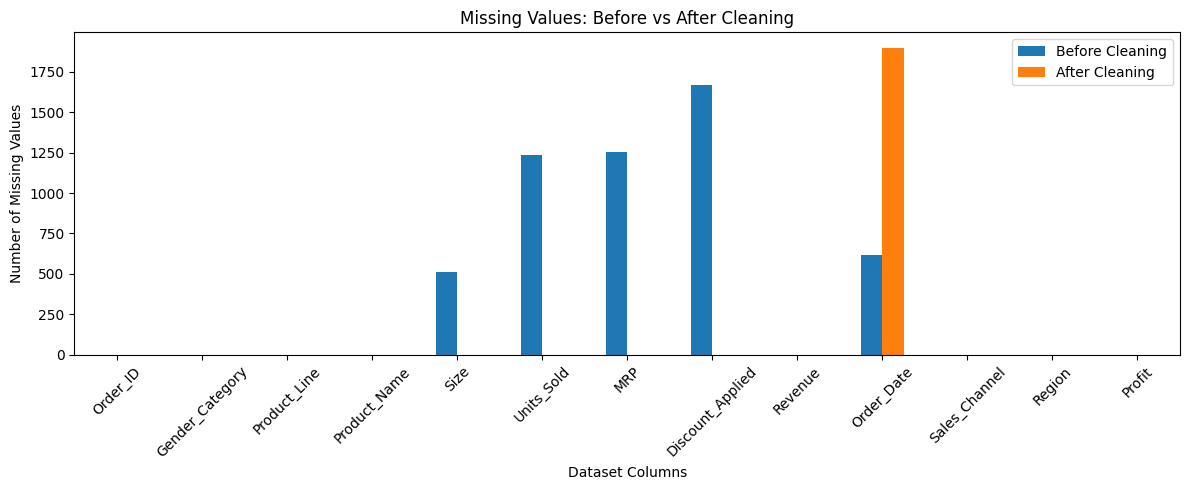

In [19]:
missing_comparison = pd.DataFrame({
    'Before Cleaning': df.isnull().sum(),
    'After Cleaning': df_clean.isnull().sum()
})

missing_comparison.plot(
    kind='bar',
    figsize=(12, 5),
    title='Missing Values: Before vs After Cleaning'
)

plt.xlabel('Dataset Columns')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## Conclusion

In this project, the Nike sales dataset was cleaned and prepared for further analysis using Python and Pandas.

The major data cleaning operations included:

- Identifying and handling missing values using median imputation and appropriate replacements.
- Converting columns into suitable data types.
- Detecting unusual values using the Interquartile Range (IQR) method.
- Identifying and correcting invalid negative values in the `Units_Sold` column.
- Preserving original MRP values and discount values that require further business-rule verification.
- Comparing the original and cleaned datasets to evaluate the improvements.

The cleaned dataset was successfully exported as a CSV file.

Overall, this project provided practical experience in data preprocessing, missing value handling, data type conversion, outlier detection, and data quality improvement.